In [1]:
import pandas as pd
import numpy as np

This jupyter notebook serves to replicate and expand on Justin Hopkin's Excel spreadsheet titled "Reaction Thermodynamics".


First order of business is replicating the tables that he had.

In [2]:
T_K = 373

Data here is from NIST
Uses reference state of 298.15K, 1 bar

# This should resemble the "Formation Energies" Tab

In [3]:
CO2_form_energy = {
        "species" : "CO2",
        'dH^0_form (kJ/mol)' : -393.5,
        'dS^0 (J/mol K)' : 213.8,
        'A' : 24.99735,
        'B' : 55.18696,
        'C' : -33.69137,
        'D' : 7.948387,
        'E' : -0.136638,
        'F' : -403.6075,
        'G' : 228.2431,
        'H' : -393.5224
    }

H2_form_energy = {
        "species" : "H2",
        'dH^0_form (kJ/mol)' : 0,
        'dS^0 (J/mol K)' : 130.68,
        'A' : 33.066178,
        'B' : -11.363417,
        'C' : 11.432816,
        'D' : -2.772874,
        'E' : -0.158558,
        'F' : -9.980797,
        'G' : 172.707974,
        'H' : 0
    }

HCOOH_form_energy = {
        "species" : "HCOOH",
        'dH^0_form (kJ/mol)' : -378.9,
        'dS^0 (J/mol K)' : 248.7,
        'A' : 19.0351279,
        'B' : 99.7317602,
        'C' : -25.23721218,
        'D' : -4.055871783,
        'E' : 0.024453839,
        'F' : 0,
        'G' : 0,
        'H' : 0
    }

H2O_form_energy = {
        "species" : "H2O",
        'dH^0_form (kJ/mol)' : -242,
        'dS^0 (J/mol K)' : 188.835,
        'A' : 30.092,
        'B' : 6.832514,
        'C' : 6.793435,
        'D' : -2.53448,
        'E' : 0.082139,
        'F' : -250.881,
        'G' : 223.3967,
        'H' : -241.8264
    }

CO_form_energy = {
        "species" : "CO",
        'dH^0_form (kJ/mol)' : -110.6,
        'dS^0 (J/mol K)' : 197.66,
        'A' : 25.56759,
        'B' : 6.09613,
        'C' : 4.054656,
        'D' : -2.671301,
        'E' : 0.131021,
        'F' : -118.0089,
        'G' : 227.3665,
        'H' : -110.5271
    }

H_form_energy = {
        "species" : "H",
        'dH^0_form (kJ/mol)' : 217.998,
        'dS^0 (J/mol K)' : 114.717,
        'A' : 20.78603,
        'B' : 4.85067E-10,
        'C' : -1.58292E-10,
        'D' : 1.5251E-11,
        'E' : 3.19635E-11,
        'F' : 211.802,
        'G' : 139.8711,
        'H' : 217.9994
    }

COOH_form_energy = {
        "species" : "COOH",
        'dH^0_form (kJ/mol)' : -162.705, #calculated
        'dS^0 (J/mol K)' : 0,
        'A' : 0,
        'B' : 0,
        'C' : 0,
        'D' : 0,
        'E' : 0,
        'F' : 0,
        'G' : 0,
        'H' : 0
    }

In [4]:
form_energetics = [CO2_form_energy, H2_form_energy, HCOOH_form_energy, H2O_form_energy, CO_form_energy, H_form_energy, COOH_form_energy]

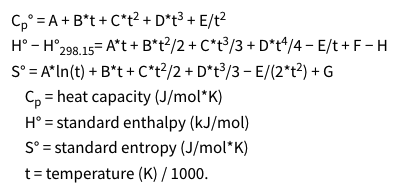

In [5]:
def shomate(T_K, species):
    A = species['A']
    B = species['B']
    C = species['C']
    D = species['D']
    E = species['E']
    F = species['F']
    G = species['G']
    H = species['H']
    std_enth = species['dH^0_form (kJ/mol)']
    std_ent = species['dS^0 (J/mol K)']

    T= T_K/1000
    T_ref = 298/1000

    enthalpy = A*T + B*T**2/2 + C*T**3/3 + D*T**4/4 - E/T + F - H + std_enth
    entropy = A*np.log(T) + B*T + C*T**2/2 + D*T**3/3 -E/(2*T**2) + G - (A*np.log(T_ref) + B*T_ref + C*T_ref**2/2 + D*T_ref**3/3 -E/(2*T_ref**2) + G) + std_ent # had to substract std state

    species['dH_f(T) (kJ/mol)'] = enthalpy
    species['dS_f(T) (J/mol K)'] = entropy

    return species

In [6]:
for species in form_energetics:
    shomate(T_K, species)

In [7]:
form_energetics_df = pd.DataFrame(form_energetics)
form_energetics_df

,species,dH^0_form (kJ/mol),dS^0 (J/mol K),A,B,C,D,E,F,G,H,dH_f(T) (kJ/mol),dS_f(T) (J/mol K)
0,CO2,-393.500,213.800,24.997350,5.518696e+01,-3.369137e+01,7.948387e+00,-1.366380e-01,-403.607500,228.243100,-393.5224,-390.600055,222.491896
1,H2,0.000,130.680,33.066178,-1.136342e+01,1.143282e+01,-2.772874e+00,-1.585580e-01,-9.980797,172.707974,0.0000,2.171836,137.191857
2,HCOOH,-378.900,248.700,19.035128,9.973176e+01,-2.523721e+01,-4.055872e+00,2.445384e-02,0.000000,0.000000,0.0000,-365.383857,259.833370
3,H2O,-242.000,188.835,30.092000,6.832514e+00,6.793435e+00,-2.534480e+00,8.213900e-02,-250.881000,223.396700,-241.8264,-239.469945,196.419377
4,CO,-110.600,197.660,25.567590,6.096130e+00,4.054656e+00,-2.671301e+00,1.310210e-01,-118.008900,227.366500,-110.5271,-108.415065,204.202965
5,H,217.998,114.717,20.786030,4.850670e-10,-1.582920e-10,1.525100e-11,3.196350e-11,211.802000,139.871100,217.9994,219.553789,119.383151
6,COOH,-162.705,0.000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.0000,-162.705000,0.000000


# This Should Resemble "Rxn Energies" Tab

In [8]:
fa_dehydrogenation_energy = {
        "rxn_name" : "Formic acid dehydrogenation",
        'rxn formula' : "HCOOH --> CO2 + H2",
        'reactants' : ['HCOOH'],
        'products' : ['CO2', 'H2']
    }

fa_dehydration_energy = {
        "rxn_name" : "Formic acid dehydration",
        'rxn formula' : "HCOOH --> CO + H2O",
        'reactants' : ['HCOOH'],
        'products' : ['CO', 'H2O']
    }

rxn_energetics_list = [fa_dehydration_energy, fa_dehydrogenation_energy]

Equations used

$dH = dH_{f, products} - dH_{f, reactants}$\
$dS = dS_{f, products} - dS_{f, reactants}$\
$\Delta G_{rxn}(T) = \sum(v_i \Delta H_i - v_i T \Delta S_i)$\
$K_eq = exp(-\frac{\Delta G_rxn}{RT})$

In [9]:
def rxn_energetics(T_K, reaction, form_energetics_df):
    enthalpy_prod = 0
    entropy_prod = 0
    enthalpy_reac = 0
    entropy_reac = 0
    for product in reaction["products"]:
        enthalpy_prod += form_energetics_df.loc[form_energetics_df["species"] == product, 'dH_f(T) (kJ/mol)'].values[0]
        entropy_prod += form_energetics_df.loc[form_energetics_df["species"] == product, 'dS_f(T) (J/mol K)'].values[0]
    for product in reaction["reactants"]:
        enthalpy_reac += form_energetics_df.loc[form_energetics_df["species"] == product, 'dH_f(T) (kJ/mol)'].values[0]
        entropy_reac += form_energetics_df.loc[form_energetics_df["species"] == product, 'dS_f(T) (J/mol K)'].values[0]
    
    enthalpy =  enthalpy_prod - enthalpy_reac
    entropy = entropy_prod - entropy_reac

    reaction["dH (kJ/mol)"] = enthalpy
    reaction["dS (J/mol K)"] = entropy
    reaction["dG (kJ/mol)"] = enthalpy - T_K * entropy/1000
    reaction["dG (eV)"] = reaction["dG (kJ/mol)"] * 1000/(1.602*10**(-19))/(6.02*10**(23))
    reaction["Keq"] = np.exp(-reaction["dG (kJ/mol)"]*1000/8.314/T_K)
    
    return reaction


In [10]:
for rxn in rxn_energetics_list:
    rxn_energetics(T_K, rxn, form_energetics_df)

In [11]:
rxn_energetics_df = pd.DataFrame(rxn_energetics_list)
rxn_energetics_df

,rxn_name,rxn formula,reactants,products,dH (kJ/mol),dS (J/mol K),dG (kJ/mol),dG (eV),Keq
0,Formic acid dehydration,HCOOH --> CO + H2O,[HCOOH],"[CO, H2O]",17.498847,140.788972,-35.015440,-0.363079,8.011485e+04
1,Formic acid dehydrogenation,HCOOH --> CO2 + H2,[HCOOH],"[CO2, H2]",-23.044362,99.850382,-60.288555,-0.625138,2.773760e+08


# Follows the tab "Adsorbates"

Products - reactants of something\
Xlookup of HCOOH in Adsorbates A7-97, find J7-97 --> for delta term\
Xlookup of HCOOH in Adsorbates A7-97, find F7-97 --> for H @ 0V\
Xlookup of HCOOH in Adsorbates A7-97, find K7-97 --> for H @ 1V\
Xlookup of HCOOH in Adsorbates A7-97, find L7-97 --> for H @ -1V\
Species needed: HCOOH, HCOOH*, COOH*, H*, CO2, CO2*, H2

In [12]:
H2_adsorbate = {
    "species" : "H2",
    "gas phase H (kJ/mol)" : H2_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "",
    "BE (eV)": 0,
    "dipole_moment (eA)" : 0,
    "polarizability (eA2/V)" : 0
}

HCOOH_adsorbate = {
    "species" : "HCOOH",
    "gas phase H (kJ/mol)" : HCOOH_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "",
    "BE (eV)": 0,
    "dipole_moment (eA)" : 0,
    "polarizability (eA2/V)" : 0
}

HCOOH_ads_adsorbate = {
    "species" : "HCOOH*",
    "gas phase H (kJ/mol)" : HCOOH_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "atop",
    "BE (eV)": -0.6,
    "dipole_moment (eA)" : 0.257,
    "polarizability (eA2/V)" : 0.273
}

COOH_ads_adsorbate = {
    "species" : "COOH*",
    "gas phase H (kJ/mol)" : COOH_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "atop",
    "BE (eV)": -2.78,
    "dipole_moment (eA)" : -0.133,
    "polarizability (eA2/V)" : 0.233
}

H_ads_adsorbate = {
    "species" : "H*",
    "gas phase H (kJ/mol)" : H_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "fcc",
    "BE (eV)": -2.79,
    "dipole_moment (eA)" : 0.012,
    "polarizability (eA2/V)" : 0.003
}

CO2_adsorbate = {
    "species" : "CO2",
    "gas phase H (kJ/mol)" : CO2_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "",
    "BE (eV)": 0,
    "dipole_moment (eA)" : 0.0,
    "polarizability (eA2/V)" : 0.0
}

CO2_ads_adsorbate = {
    "species" : "CO2*",
    "gas phase H (kJ/mol)" : CO2_form_energy["dH_f(T) (kJ/mol)"],
    "site" : "bridge",
    "BE (eV)": -0.27,
    "dipole_moment (eA)" : 0.025,
    "polarizability (eA2/V)" : 0.155
}

adsorbate_list = [H2_adsorbate, H_ads_adsorbate, CO2_adsorbate, CO2_ads_adsorbate, COOH_ads_adsorbate, HCOOH_adsorbate, HCOOH_ads_adsorbate]

# Don't understand the math here

In [13]:
def adsorbate_electronics(adsorbate, V, bond_length):
    adsorbate["dH(0 V) (kJ/mol)"] = adsorbate["gas phase H (kJ/mol)"] + adsorbate["BE (eV)"]*1.602E-19*6.02E23/1000
    adsorbate["dV_WF (eV)"] = adsorbate["dipole_moment (eA)"] * 10**(-10) * 1.602E-19 * 10**19 / 0.00000000000885
    adsorbate["delta (e-/ads)"] = adsorbate["dipole_moment (eA)"] / 0.5
    adsorbate["dH (V1) (kJ/mol)"] = adsorbate["dH(0 V) (kJ/mol)"] - (-V/bond_length) * (adsorbate["dipole_moment (eA)"] + 0.5 * adsorbate["polarizability (eA2/V)"] * (-V/bond_length)) * 1.602E-19 * 6.02E23 / 1000
    adsorbate["% change in BE"] = 100*(adsorbate["dH (V1) (kJ/mol)"] - adsorbate["dH(0 V) (kJ/mol)"])/abs(adsorbate["dH(0 V) (kJ/mol)"])
    return adsorbate

In [14]:
for adsorbate in adsorbate_list:
    adsorbate_electronics(adsorbate, 0.5, 0.5)

adsorbate_df = pd.DataFrame(adsorbate_list)
adsorbate_df

,species,gas phase H (kJ/mol),site,BE (eV),dipole_moment (eA),polarizability (eA2/V),dH(0 V) (kJ/mol),dV_WF (eV),delta (e-/ads),dH (V1) (kJ/mol),% change in BE
0,H2,2.171836,,0.00,0.000,0.000,2.171836,0.000000,0.000,2.171836,0.000000
1,H*,219.553789,fcc,-2.79,0.012,0.003,-49.514927,0.217220,0.024,-48.502303,2.045089
2,CO2,-390.600055,,0.00,0.000,0.000,-390.600055,0.000000,0.000,-390.600055,0.000000
3,CO2*,-390.600055,bridge,-0.27,0.025,0.155,-416.638963,0.452542,0.050,-421.702084,-1.215230
4,COOH*,-162.705000,atop,-2.78,-0.133,0.233,-430.809312,-2.407525,-0.266,-454.871192,-5.585274
5,HCOOH,-365.383857,,0.00,0.000,0.000,-365.383857,0.000000,0.000,-365.383857,0.000000
6,HCOOH*,-365.383857,atop,-0.60,0.257,0.273,-423.248097,4.652136,0.514,-411.627029,2.745687


### "Reactions" Tab

In [15]:
fa_dehydrogenation_coord = {
    'start' : 'HCOOH',
    'steps' : ['step 1 surf' , 'step 2 surf', 'step 3 surf', 'step 4 surf', 'step 5 surf'],
    'step 1': [['HCOOH'],['HCOOH*']],
    'step 2': [['HCOOH*'],['COOH*', 'H*']],
    'step 3': [['COOH*'],['CO2*', 'H*']],
    'step 4': [['CO2*'],['CO2']],
    'step 5': [['H*', 'H*'],['H2']],
    'step 1 surf': ['HCOOH*'],
    'step 2 surf': ['COOH*', 'H*'],
    'step 3 surf': ['CO2*', 'H*', 'H*'],
    'step 4 surf': ['CO2', 'H*', 'H*'],
    'step 5 surf': ['CO2', 'H2']
}

In [16]:
def rxn_coord_energetics(rxn_coord, V):
    for step in rxn_coord["steps"]:
        rxn_coord[f"start H @ 0 V (kJ/mol)"] = adsorbate_df.loc[adsorbate_df['species'] == rxn_coord['start'], 'dH(0 V) (kJ/mol)'].values[0]

        species_enth = 0
        for species in rxn_coord[step]:
            species_enth += adsorbate_df.loc[adsorbate_df['species'] == species, 'dH(0 V) (kJ/mol)'].values[0]

        rxn_coord[f"{step} H @ 0 V (kJ/mol)"] = species_enth
        #rxn_coord[f"start H @ 0 V (kJ/mol)"] = adsorbate_df.loc[adsorbate_df['species'] == rxn_coord['start'], 'dH(0 V) (kJ/mol)'].values[0]

    return
    

In [17]:
rxn_coord_energetics(fa_dehydrogenation_coord, 0)
fa_dehydrogenation_coord

{'start': 'HCOOH',
 'steps': ['step 1 surf',
  'step 2 surf',
  'step 3 surf',
  'step 4 surf',
  'step 5 surf'],
 'step 1': [['HCOOH'], ['HCOOH*']],
 'step 2': [['HCOOH*'], ['COOH*', 'H*']],
 'step 3': [['COOH*'], ['CO2*', 'H*']],
 'step 4': [['CO2*'], ['CO2']],
 'step 5': [['H*', 'H*'], ['H2']],
 'step 1 surf': ['HCOOH*'],
 'step 2 surf': ['COOH*', 'H*'],
 'step 3 surf': ['CO2*', 'H*', 'H*'],
 'step 4 surf': ['CO2', 'H*', 'H*'],
 'step 5 surf': ['CO2', 'H2'],
 'start H @ 0 V (kJ/mol)': np.float64(-365.3838570983642),
 'step 1 surf H @ 0 V (kJ/mol)': np.float64(-423.2480970983642),
 'step 2 surf H @ 0 V (kJ/mol)': np.float64(-480.3242388100546),
 'step 3 surf H @ 0 V (kJ/mol)': np.float64(-515.668816947414),
 'step 4 surf H @ 0 V (kJ/mol)': np.float64(-489.62990894741404),
 'step 5 surf H @ 0 V (kJ/mol)': np.float64(-388.4282193217411)}

### Plotting

In [34]:
def rxn_coord_plotter(rxn_coord):
    enth_0V = []
    enth_pos = []
    enth_neg = []

    enth_0V.append(rxn_coord['start H @ 0 V (kJ/mol)'].values[0])

    filter_str = ["step", "surf", "V", "+", "-", "0"]
    for key, value in rxn_coord.items():
        print(key)
        if ("step" and "surf" and "V" and "0") in key and "start" not in key:
            enth_0V.append(value)
        if ("step" and "surf" and "V" and "+") in key and "start" not in key:
            enth_pos.append(value)
        if ("step" and "surf" and "V" and "-") in key and "start" not in key:
            enth_neg.append(value)
    return enth_0V, 

In [35]:
rxn_coord_plotter(fa_dehydrogenation_coord)

AttributeError: 'numpy.float64' object has no attribute 'values'

for 

In [44]:
shomate(T_K, CO2_form_energy)

{'species': 'CO2',
 'dH^0_form (kJ/mol)': -393.5,
 'dS^0 (J/mol K)': 213.8,
 'A': 24.99735,
 'B': 55.18696,
 'C': -33.69137,
 'D': 7.948387,
 'E': -0.136638,
 'F': -403.6075,
 'G': 228.2431,
 'H': -393.5224,
 'dH_f(T) (kJ/mol)': -390.60005532730474,
 'dS_f(T) (J/mol K)': np.float64(436.26084669106086)}

In [39]:
print(shomate(T_K, CO2_form_energy)) #kJ/mol

(-390.60005532730474, np.float64(436.26084669106086))


In [41]:
5*entropy

np.float64(2181.3042334553043)

In [11]:
form_list = [CO2_form_energy, CO3_form_energy]

In [13]:
form_energies = pd.DataFrame(form_list)
form_energies

,species,dH^0_form (kJ/mol),dS^0 (J/mol K),A,B,C,D,E,F,G,H
0,CO2,-395.5,213.8,24.99735,55.18696,-33.69137,7.948387,-0.136638,-403.6075,228.2431,-393.5224
1,CO2,-395.5,213.8,24.99735,55.18696,-33.69137,7.948387,-0.136638,-403.6075,228.2431,-393.5224
